<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_099_qkv_self_attention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 99/365 — Self-Attention: Query, Key & Value

Yesterday we built a small Transformer.

Today we open up the most important mechanism inside it:

**Self-Attention**

Specifically:

- Query (Q)
- Key (K)
- Value (V)

We use a real sunspot sequence and implement single-head attention manually.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from statsmodels.datasets import sunspots


## 1. Load and prepare the real dataset

In [2]:
data = sunspots.load_pandas().data.copy()

years = data["YEAR"].astype(int).values
values = data["SUNACTIVITY"].astype(np.float32).values.reshape(-1,1)

split = int(len(values) * 0.8)

scaler = MinMaxScaler()
scaler.fit(values[:split])

scaled = scaler.transform(values)

sequence_length = 12

X, y = [], []

for i in range(len(scaled) - sequence_length):
    X.append(scaled[i:i+sequence_length])
    y.append(scaled[i+sequence_length])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

target_indices = np.arange(sequence_length, len(scaled))

train_mask = target_indices < split
test_mask = target_indices >= split

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]


In [3]:
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train),
        torch.tensor(y_train)
    ),
    batch_size=32,
    shuffle=True
)


## 2. Q, K and V intuition

For each position, the model creates three vectors.

**Query**

`Q = XWq`

Think: **What am I looking for?**

**Key**

`K = XWk`

Think: **What information do I contain?**

**Value**

`V = XWv`

Think: **What information should I pass forward if selected?**


## 3. The core equation

`Attention(Q,K,V) = softmax(QKᵀ / √dₖ)V`

Step by step:

1. Query compares with Keys.
2. Dot products become similarity scores.
3. Divide by `√dₖ`.
4. Apply Softmax.
5. Use those weights to combine the Values.


## 4. Build single-head self-attention manually

In [4]:
class SingleHeadAttentionModel(nn.Module):

    def __init__(
        self,
        sequence_length=12,
        d_model=12,
        d_k=6
    ):
        super().__init__()

        self.d_k = d_k

        self.input_projection = nn.Linear(
            1,
            d_model
        )

        self.position = nn.Parameter(
            torch.randn(
                1,
                sequence_length,
                d_model
            ) * 0.02
        )

        self.Wq = nn.Linear(
            d_model,
            d_k,
            bias=False
        )

        self.Wk = nn.Linear(
            d_model,
            d_k,
            bias=False
        )

        self.Wv = nn.Linear(
            d_model,
            d_k,
            bias=False
        )

        self.output = nn.Linear(
            d_k,
            1
        )

    def forward(
        self,
        x,
        return_parts=False
    ):

        z = (
            self.input_projection(x)
            + self.position
        )

        Q = self.Wq(z)
        K = self.Wk(z)
        V = self.Wv(z)

        scores = (
            Q @ K.transpose(-2,-1)
        ) / np.sqrt(self.d_k)

        attention_weights = torch.softmax(
            scores,
            dim=-1
        )

        context = (
            attention_weights @ V
        )

        pooled = context.mean(dim=1)

        prediction = self.output(
            pooled
        )

        if return_parts:
            return (
                prediction,
                Q,
                K,
                V,
                scores,
                attention_weights,
                context
            )

        return prediction


## 5. Train the model

In [5]:
torch.manual_seed(42)

model = SingleHeadAttentionModel()

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.005
)

epochs = 60

for epoch in range(epochs):

    model.train()

    for xb, yb in train_loader:

        optimizer.zero_grad()

        prediction = model(xb)

        loss = criterion(
            prediction,
            yb
        )

        loss.backward()

        optimizer.step()


## 6. Evaluate and expose Q, K, V

In [6]:
model.eval()

with torch.no_grad():

    (
        prediction_scaled,
        Q,
        K,
        V,
        scores,
        attention_weights,
        context
    ) = model(
        torch.tensor(X_test),
        return_parts=True
    )

prediction = scaler.inverse_transform(
    prediction_scaled.numpy()
)

actual = scaler.inverse_transform(
    y_test
)

test_years = years[
    target_indices[test_mask]
]

mae = mean_absolute_error(
    actual.ravel(),
    prediction.ravel()
)

print("Test MAE:", round(mae,2))


Test MAE: 16.64


## 7. Inspect tensor shapes

In [7]:
print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)
print("Scores shape:", scores.shape)
print("Attention shape:", attention_weights.shape)
print("Context shape:", context.shape)


Q shape: torch.Size([62, 12, 6])
K shape: torch.Size([62, 12, 6])
V shape: torch.Size([62, 12, 6])
Scores shape: torch.Size([62, 12, 12])
Attention shape: torch.Size([62, 12, 12])
Context shape: torch.Size([62, 12, 6])


For one sample with 12 positions:

- Q has 12 query vectors
- K has 12 key vectors
- V has 12 value vectors
- QKᵀ produces a `12 × 12` score matrix


## 8. Visualize the attention matrix

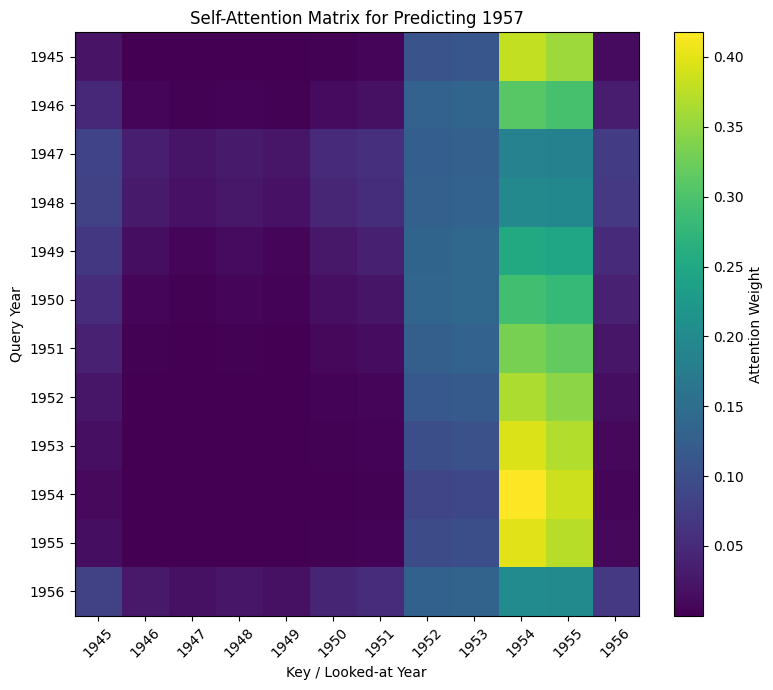

In [8]:
example_idx = min(
    10,
    len(X_test)-1
)

weights = (
    attention_weights[example_idx]
    .numpy()
)

target_year = test_years[
    example_idx
]

input_years = np.arange(
    target_year - sequence_length,
    target_year
)

plt.figure(figsize=(8,7))

plt.imshow(
    weights,
    aspect="auto"
)

plt.colorbar(
    label="Attention Weight"
)

plt.xticks(
    range(sequence_length),
    input_years,
    rotation=45
)

plt.yticks(
    range(sequence_length),
    input_years
)

plt.xlabel("Key / Looked-at Year")
plt.ylabel("Query Year")

plt.title(
    f"Self-Attention Matrix for Predicting {target_year}"
)

plt.tight_layout()
plt.show()


## 9. Inspect one Query

Take the final query position.

Compute:

`query · every key`

Then scale and apply Softmax.

That produces one row of the attention matrix.


In [9]:
query = (
    Q[example_idx, -1]
    .numpy()
)

keys = (
    K[example_idx]
    .numpy()
)

similarities = (
    query @ keys.T
) / np.sqrt(
    query.shape[0]
)

weights_one_query = np.exp(
    similarities - similarities.max()
)

weights_one_query = (
    weights_one_query
    / weights_one_query.sum()
)

print(
    np.round(
        weights_one_query,
        3
    )
)


[0.08  0.029 0.018 0.025 0.019 0.043 0.052 0.13  0.132 0.201 0.199 0.07 ]


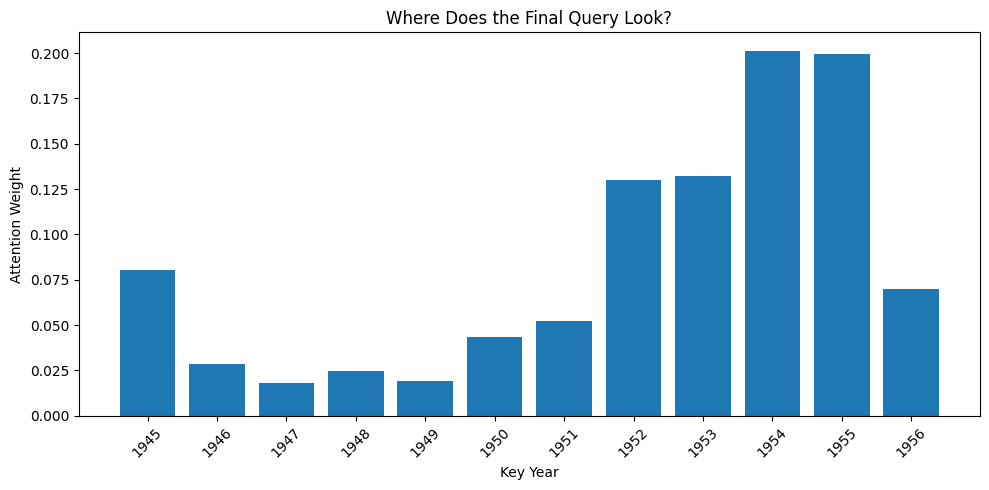

In [10]:
plt.figure(figsize=(10,5))

plt.bar(
    input_years,
    weights_one_query
)

plt.xlabel("Key Year")
plt.ylabel("Attention Weight")

plt.title(
    "Where Does the Final Query Look?"
)

plt.xticks(
    input_years,
    rotation=45
)

plt.tight_layout()
plt.show()


## 10. Why divide by √dₖ?

As vector dimension increases, dot products can become large.

Large scores can make Softmax extremely sharp.

Scaling by:

`√dₖ`

keeps the score magnitude more stable.


## Simple takeaway

Self-attention is:

`QKᵀ`

→ similarity scores

→ scaling

→ Softmax

→ weights

→ multiply by `V`

> **Query asks. Key matches. Value delivers.**


## References

- Attention Is All You Need:
  https://arxiv.org/abs/1706.03762

- PyTorch MultiheadAttention:
  https://pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html

- The Illustrated Transformer:
  https://jalammar.github.io/illustrated-transformer/
